# Talent abilities: overview

This notebook compares every new talent ability (Parasite → Soul Reflection in
`client/src/ui/visuals/spell_icons.rs`) on one axis: the caster's **modified skill**
(`skill[n][5]`). Each ability has a dedicated notebook in this folder with the full formula,
validation against the Rust unit tests, and detailed plots. This page answers three
cross-cutting questions:

1. **Where does each ability stop scaling?** The skill value at which its primary effect hits a
   clamp.
2. **How does scaling compare within a class?** Each primary effect is normalised to its value
   at skill 200.
3. **Soul Reflection.** It has no scaling output, only a `power ≥ resist` threshold, so it is
   charted here instead of getting its own notebook.

| Class | Ability | Notebook | Primary effect plotted here |
|---|---|---|---|
| Mercenary | Parasite | `mercenary_parasite.ipynb` | DoT HP/s per target |
| | Contagion | `mercenary_contagion.ipynb` | DoT HP/s per target |
| | Gunpowder Flash | `mercenary_gunpowder_flash.ipynb` | enemy action-speed points removed |
| | Disarm | `mercenary_disarm.ipynb` | enemy weapon-skill penalty |
| | Deliver Death | `mercenary_deliver_death.ipynb` | damage scale % |
| | Blade Dance | `mercenary_blade_dance.ipynb` | damage scale % (active only) |
| Templar | Rains of Renewal | `templar_rains_of_renewal.ipynb` | HP/s healed |
| | Gash | `templar_gash.ipynb` | fixed damage multiple of WV |
| | Sun's Blessing | `templar_suns_blessing.ipynb` | bonus to attributes / armor / WV |
| | Seeing Red | `templar_seeing_red.ipynb` | buff duration |
| | Thunderous Fury | `templar_thunderous_fury.ipynb` | mean raw damage per target |
| | Inner Strength | `templar_inner_strength.ipynb` | weapon-skill bonus |
| Harakim | Lava Blast | `harakim_lava_blast.ipynb` | direct + full burn damage |
| | Ice Stun | `harakim_ice_stun.ipynb` | stun duration |
| | Anguish – Lava | `harakim_anguish_lava.ipynb` | next-Blast multiplier |
| | Anguish – Ice | `harakim_anguish_ice.ipynb` | armor & WV penalty |
| | Revenant Conduit | `harakim_revenant_conduit.ipynb` | companion skill boost % |
| | Spectral Pact | `harakim_spectral_pact.ipynb` | damage redirect % |
| Aura | Aura of Despair | `aura_of_despair.ipynb` | attribute penalty |
| | War Banner | `aura_war_banner.ipynb` | armor & WV bonus |

Skipped, per `PLAN.md` §3: Kindred Spirit / Spellcaster Kindred Spirit, Anguish – Earth, Element
Switching (a flat +20%, covered in the Lava Blast and Ice Stun notebooks), and the Seyan'Du
runes.

All curves below assume a target with **0 immunity**, a **Mercenary** caster for Mercenary
spells, and a **Harakim** caster for Harakim spells. Abilities that read the raw skill (Gash,
Rains, Sun's Blessing, Seeing Red, Thunderous Fury, Inner Strength, Anguish, companion spells and
auras) ignore race.

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
P_WIDE = np.arange(1, 1001)   # used only to locate saturation points beyond 200

# Primary effects

Each entry is the compact form of the formula derived and validated in that ability's notebook.

In [2]:
def merc(p):
    return mm.spell_power(p, 0, "Mercenary")


def hara(p):
    return mm.spell_power(p, 0, "Harakim")


def aura_power(p):
    return 50 + mm.idiv(p, 2)


ABILITIES = {
    "Mercenary": {
        "Parasite (HP/s)": lambda p: mm.dot_tick(merc(p), "parasite"),
        "Contagion (HP/s)": lambda p: mm.dot_tick(merc(p), "contagion"),
        "Gunpowder Flash (slow pts)": lambda p: mm.clamp(3 + mm.idiv(merc(p), 40), 6, 20),
        "Disarm (−weapon skill)": lambda p: mm.clamp(mm.idiv(merc(p), 2) * 3, 3, 150),
        "Deliver Death / Blade Dance (scale %)": lambda p: mm.clamp(50 + mm.idiv(p, 2), 50, 150),
    },
    "Templar": {
        "Rains of Renewal (HP/s)": lambda p: mm.dot_tick(p),
        "Gash (×WV fixed part)": lambda p: (100 + mm.clamp(np.asarray(p) * 3, 30, 600)) / 100,
        "Sun's Blessing (+all)": lambda p: mm.clamp((mm.idiv(p, 10) + 2) * 3, 3, 90),
        "Seeing Red (duration s)": lambda p: 15 + mm.clamp(mm.idiv(p, 5), 0, 75),
        "Thunderous Fury (mean raw dmg)": lambda p: (lambda b: b + mm.rand_mod_mean(b))(np.maximum(1, mm.idiv(np.asarray(p) * 3, 4))),
        "Inner Strength (+weapon skill)": lambda p: mm.clamp((mm.idiv(p, 5) + 2) * 3, 3, 150),
    },
    "Harakim": {
        "Lava Blast (direct + burn)": lambda p: 2 * hara(p) + 15 * mm.dot_tick(hara(p), "lava"),
        "Ice Stun (stun s)": lambda p: (hara(p) + mm.TICKS) / mm.TICKS,
        "Anguish – Lava (Blast ×%)": lambda p: mm.clamp(150 + mm.idiv(p, 2), 150, 200),
        "Anguish – Ice (−armor/WV)": lambda p: mm.clamp(mm.idiv(p, 8), 2, 30),
        "Revenant Conduit (boost %)": lambda p: mm.clamp(mm.idiv(p, 10) * 30, 30, 150),
        "Spectral Pact (redirect %)": lambda p: mm.clamp(30 + mm.idiv(np.asarray(p) * 45, 100), 30, 75),
    },
    "Aura": {
        "Aura of Despair (−attributes)": lambda p: mm.idiv(aura_power(p), 3),
        "War Banner (+armor/WV)": lambda p: np.maximum(1, mm.idiv(aura_power(p), 10)),
    },
}

# Validation

These spot checks pin the compact forms to the values asserted in the Rust unit tests and in the
per-ability notebooks.

In [3]:
A = {name: f for group in ABILITIES.values() for name, f in group.items()}
assert mm.clamp(3 + mm.idiv(0, 40), 6, 20) == 6 and mm.clamp(3 + mm.idiv(400, 40), 6, 20) == 13
assert A["Deliver Death / Blade Dance (scale %)"](100) == 100
assert A["Deliver Death / Blade Dance (scale %)"](400) == 150
assert mm.clamp(mm.idiv(40, 2) * 3, 3, 150) == 60      # Disarm, power 40 -> -60
assert A["Anguish – Lava (Blast ×%)"](25) == 162
assert A["Anguish – Lava (Blast ×%)"](500) == 200
assert A["Spectral Pact (redirect %)"](1000) == 75
assert A["Revenant Conduit (boost %)"](1000) == 150
print("overview formulas OK")

overview formulas OK


# Where does each ability stop scaling?

"Saturates at" is the lowest modified skill at which the primary effect reaches its ceiling. It
is searched up to skill 1000. A dash means the effect never stops growing.

In [4]:
rows = []
for cls, group in ABILITIES.items():
    for name, f in group.items():
        v = np.asarray(f(P_WIDE), dtype=float)
        sat = "—"
        if v[-1] == v[-200:].min() and np.ptp(v[-200:]) == 0:
            sat = int(P_WIDE[np.argmax(v == v[-1])])
        rows.append((cls, name, float(np.asarray(f(105))), float(np.asarray(f(120))), float(np.asarray(f(200))), sat))

print(f"{'class':<10} {'ability':<40} {'@105':>8} {'@120':>8} {'@200':>8}  saturates at")
for cls, name, a, b, c, sat in rows:
    print(f"{cls:<10} {name:<40} {a:>8.1f} {b:>8.1f} {c:>8.1f}  {sat}")

class      ability                                      @105     @120     @200  saturates at
Mercenary  Parasite (HP/s)                              82.0     94.0    157.0  —
Mercenary  Contagion (HP/s)                            164.0    188.0    314.0  —
Mercenary  Gunpowder Flash (slow pts)                    6.0      6.0      8.0  648
Mercenary  Disarm (−weapon skill)                      150.0    150.0    150.0  96
Mercenary  Deliver Death / Blade Dance (scale %)       102.0    110.0    150.0  200
Templar    Rains of Renewal (HP/s)                      78.0     90.0    150.0  —
Templar    Gash (×WV fixed part)                         4.2      4.6      7.0  200
Templar    Sun's Blessing (+all)                        36.0     42.0     66.0  280
Templar    Seeing Red (duration s)                      36.0     39.0     55.0  375
Templar    Thunderous Fury (mean raw dmg)              116.5    134.5    224.5  —
Templar    Inner Strength (+weapon skill)               69.0     78.0    126

# Normalised scaling per class

Each curve is divided by its own value at skill 200. A curve that reaches 1.0 before the right
edge has saturated, and further skill is wasted on that ability. A curve still rising at 200
keeps rewarding investment.

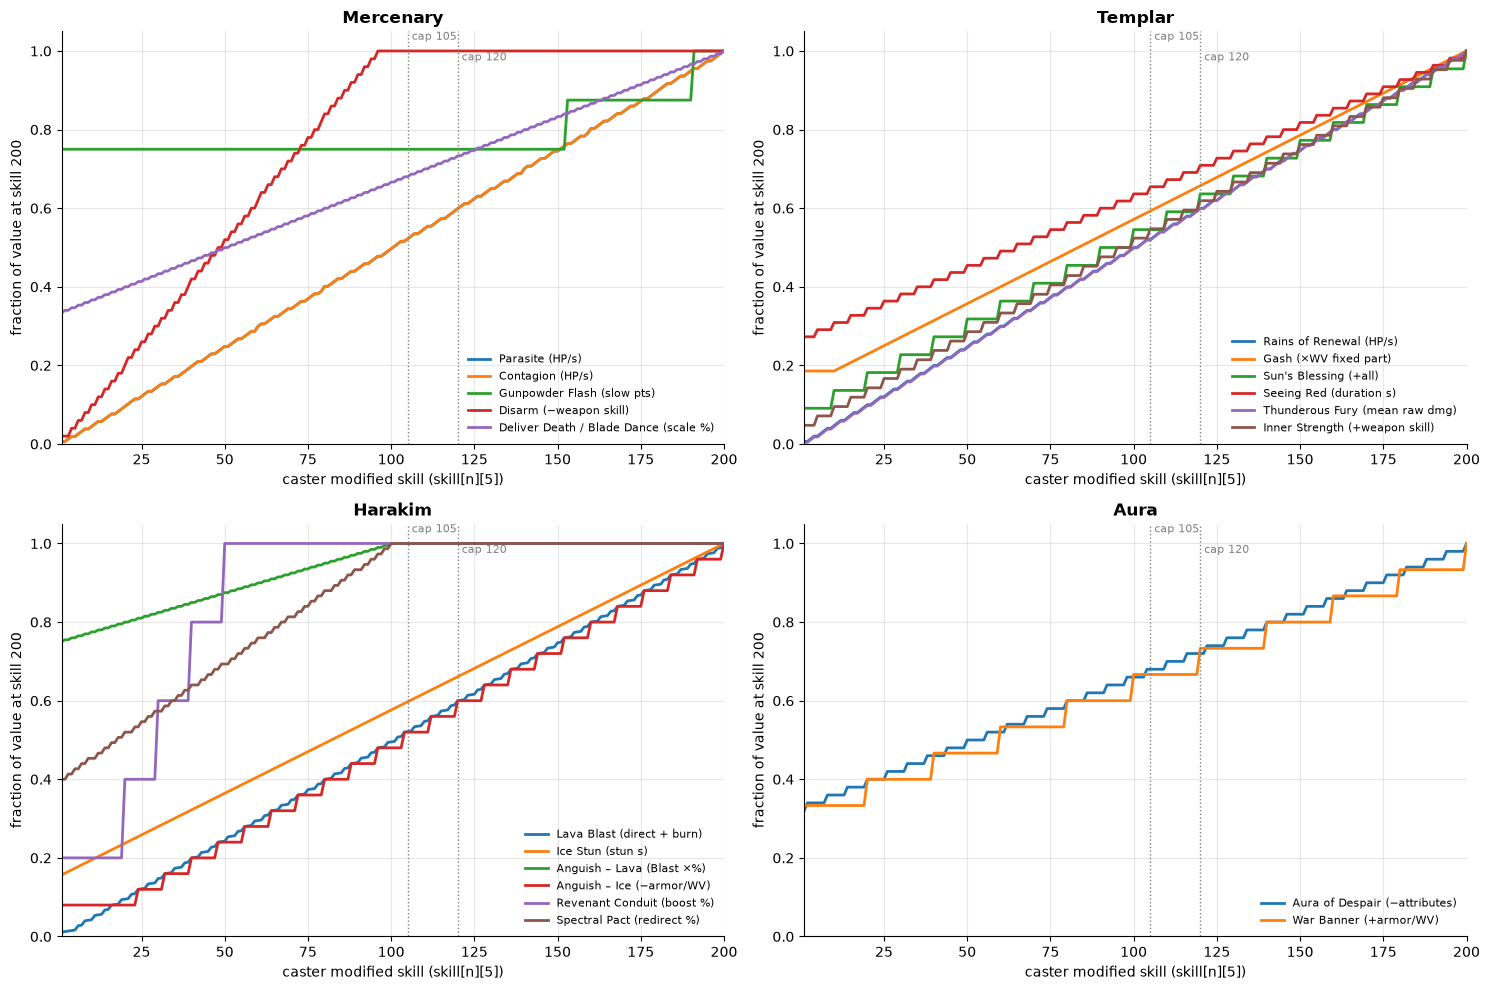

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (cls, group) in zip(axes.flat, ABILITIES.items()):
    for name, f in group.items():
        v = np.asarray(f(P), dtype=float)
        ax.plot(P, v / v[-1], label=name)
    mm.skill_axis(ax, "fraction of value at skill 200", cls)
    mm.mark_caps(ax)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

# Soul Reflection: landing threshold

Soul Reflection (150 endurance, 30 s cooldown, radius 8, NPCs only) routs every NPC whose
effective resist does not exceed the caster's modified skill:

$$
\text{routed} \iff p \ \ge\ \left\lfloor \frac{100 \cdot \text{Resist}}{100 + \text{pen}\%} \right\rfloor
$$

Players are never affected. A routed NPC flees for a fixed 10 s, so the skill only decides
**which** NPCs flee, not how long. With spell penetration, the highest affected Resist grows to
roughly $p\,(100 + \text{pen})/100$.

Source: `server/src/driver/skill/auras.rs::skill_soul_reflection`.

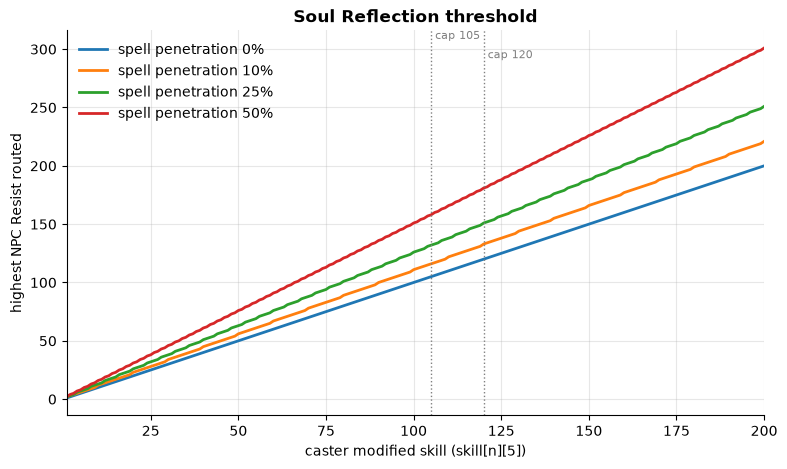

In [6]:
def max_resist_routed(p, pen=0):
    """Largest target Resist value that Soul Reflection still routs."""
    r = np.arange(0, 1001)
    eff = mm.effective_resist(r, pen)
    ok = np.asarray(eff)[None, :] <= np.asarray(p)[:, None]
    return np.where(ok.any(axis=1), r[np.argmax(~ok, axis=1) - 1], -1)


assert max_resist_routed(np.array([50]))[0] == 50          # resist == power is routed
assert max_resist_routed(np.array([100]), 25)[0] == 126    # 126*100/125 = 100

fig, ax = plt.subplots()
for pen in (0, 10, 25, 50):
    ax.plot(P, max_resist_routed(P, pen), label=f"spell penetration {pen}%")
mm.skill_axis(ax, "highest NPC Resist routed", "Soul Reflection threshold")
mm.mark_caps(ax)
ax.legend()

# Observations

## Scaling

- **Early saturation.** Revenant Conduit saturates at skill 50, Spectral Pact and
  Anguish – Lava at 100, and Disarm at about 96 for a Mercenary caster (the race ×1.05 applies
  before the clamp). Raising these past the raise caps (105/120) does nothing.
- **Effective saturation before the clamp.** Inner Strength's clamp is at 240, but +42 Weapon
  Skill (skill 60) already pins the melee hit table against an equal opponent. Disarm has the same
  problem from the defender's side.
- **Flat in practice.** Gunpowder Flash sits on its 6-point floor until p′ reaches 120, so a
  skill-1 Flash and a skill-115 Flash slow by the same amount. Seeing Red's skill only buys
  duration; the bonus itself is 3× the current weapon value.
- **Deliver Death, Blade Dance and Gash** saturate at exactly skill 200. Characters with heavy
  skill gear still gain from them, but the gain stops abruptly.
- **Unbounded abilities.** Parasite, Contagion, Rains, Thunderous Fury, Lava Blast, Ice Stun and
  both auras grow linearly. Only target Immunity bounds them, and only for spells that use
  `spell_immunity`. Rains, Thunderous Fury, the Ice Stun burst and both auras skip Immunity.
- **Soul Reflection** routs any NPC whose Resist is at most the caster's skill, and spell
  penetration stretches that further. Its cost is flat, so the skill only moves the threshold.

## Power outliers

| Ability | Headline (details in the ability notebook) |
|---|---|
| Blade Dance | The passive amplifier on Surround Hit does about 12× the active over 30 s, and ignores the skill value |
| Disarm | −Weapon Skill on the target with near-100% uptime; saturates at ~96 |
| Sun's Blessing | Free and permanent at skill 105: +36 to all attributes, armor and WV (−79% incoming, ×2 outgoing in the reference fight) |
| Seeing Red | +3× WV, multiplies with Sun's Blessing; ×2.7 sustained damage |
| Inner Strength | 95% / 5% hit chances in an even fight at 105; 100% uptime |
| Rains of Renewal | 78 HP/s self heal at 105 with near-100% uptime and no counterplay |
| Lava Blast | The armor-proof 15 s burn (585 HP at 105) is about 5× the hit; splash targets burn too |
| Ice Stun | Free, armor-ignoring 157 HP burst on 8 tiles per marked death, which can chain |
| Spectral Pact | Redirect taken before the owner's armor: an armor-20 owner takes ~3% of a typical hit at the cap, armor 40 takes none |
| Aura of Despair | Free, roll-less, Immunity-proof −34 to every attribute in 12 tiles at 105; stacks with Curse |

## Defects and inconsistencies found

- **Parasite and Contagion:** death spread applies Immunity and race a second time to the copy's power.
- **Anguish (Lava) and Anguish (Ice):** no talent grants either skill. Anguish (Ice)'s
  description says 30 mana, but the code charges 35.
- **Anguish (Lava) and Lava Blast:** they cannot combine. Lava Blast replaces Blast and never
  consumes the marker. A marked Blast also costs about twice the mana, because its cost is computed
  from the multiplied damage.
- **Blast:** the `cast_blast_effect` doc comment says it rolls a resist chance; it doesn't.
- **Gash:** the comment in `skill_gash` describing the HP cost is stale.
- **Aura of Despair:** it targets by group only, with no `may_aoe_attack` check. It curses the
  caster's own ghost companions, and town NPCs or players in other groups, silently.
- **War Banner:** it does not buff the caster's own ghost companions.
- **Revenant Conduit:** the 25 endurance is checked but never spent. This is harmless; the drain is
  1 per second.